Лабораторная работа №7. Эмбеддинги, чанки и метрики
расстояний
Цель: освоить разбиение текста на чанки, работу с эмбеддингами и сравнение метрик расстояний.
Задачи:
1. Проанализировать готовые чанки: размеры, распределение по документам.
2. Разбить исходные документы разными стратегиями и сравнить с готовыми чанками.
3. Посчитать метрики расстояний: cosine, euclidean, cityblock, dot product.
4. Сравнить метрики: где порядок соседей совпадает, где расходится.
5. Применить L2-нормализацию и посмотреть, что меняется.
6. Сделать поиск по чанкам и оценить качество.

Библиотеки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cosine, euclidean, cityblock
from sklearn.preprocessing import Normalizer, StandardScaler
from sklearn.decomposition import PCA

np.random.seed(42)
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
print('OK')

OK


Данные
В работе нужны два файла: documents.csv и chunks_embeddings.csv . Если их нет в LMS — создайте сами, запустив
код ниже. Оба файла появятся в текущей папке.

In [3]:
docs = [
    {'doc_id': 1, 'title': 'Введение в машинное обучение',
     'text': ('Машинное обучение – это область искусственного интеллекта, которая изучает методы построения моделей, '
              'способных обучаться на данных. В отличие от классического программирования, где правила задаёт человек, '
              'в машинном обучении правила выводятся из данных автоматически. Основные типы задач: классификация, '
              'регрессия, кластеризация. Классификация предсказывает категорию, например, спам или не спам. '
              'Регрессия предсказывает число, например, цену квартиры. Кластеризация разбивает объекты на группы '
              'похожих. Обучение делится на обучение с учителем и без учителя. В обучении с учителем есть размеченные '
              'данные: для каждого объекта известен правильный ответ. В обучении без учителя разметки нет, модель '
              'сама находит структуру. Качество модели проверяют на отложенной выборке – тесте. Основные метрики '
              'классификации: accuracy, precision, recall, F1. Для регрессии: MAE, RMSE. Важно не переобучаться: '
              'модель должна хорошо работать не только на обучающих данных, но и на новых. Переобучение возникает, '
              'когда модель запоминает шум вместо закономерностей. Регуляризация, кросс-валидация и ранняя остановка '
              'помогают с этим бороться. Популярные библиотеки: scikit-learn, XGBoost, LightGBM, PyTorch.')},
    {'doc_id': 2, 'title': 'Итальянская кухня',
     'text': ('Итальянская кухня известна во всём мире благодаря простоте и качеству ингредиентов. Основные продукты: '
              'оливковое масло, томаты, базилик, пармезан, чеснок. Паста – один из символов итальянской кухни. '
              'Спагетти, пенне, фарфалле, ригатони – сотни форм, у каждой своё назначение. Соусы подбираются под форму '
              'пасты: густые к короткой, жидкие к длинной. Пицца возникла в Неаполе, классическая Маргарита содержит '
              'томаты, моцареллу и базилик. Тесто для пиццы должно выстаиваться не менее суток. Ризотто готовят из '
              'риса арборио, постепенно добавляя бульон. Лазанья – слои теста, мясного соуса и бешамели. Тирамису '
              'состоит из савоярди, кофе, маскарпоне и какао. Итальянцы пьют эспрессо стоя у барной стойки, '
              'капучино – только утром. Сыры: пармезан, горгонзола, пекорино, моцарелла. Вина: кьянти, бароло, '
              'просекко. Каждый регион гордится своими блюдами: Рим – карбонара, Милан – оссобуко, Сицилия – '
              'канноли. Приём пищи в Италии – это ритуал, а не просто еда.')},
    {'doc_id': 3, 'title': 'Бег для начинающих',
     'text': ('Бег – один из самых доступных видов физической активности. Для начала достаточно кроссовок и '
              'желания. Первые тренировки должны быть короткими: 15–20 минут в лёгком темпе. Главное правило – '
              'не гнаться за скоростью. Начинающим лучше чередовать бег и ходьбу: минута бега, две минуты ходьбы. '
              'Постепенно время бега увеличивается. Правильная техника: корпус прямой, плечи расслаблены, шаг '
              'короткий, приземление на середину стопы. Дыхание должно быть ровным и глубоким. Разминка перед '
              'бегом и растяжка после – обязательны. Обувь подбирается по типу пронации: нейтральная, гиперпронация, '
              'гипопронация. Нельзя увеличивать объём больше, чем на 10 процентов в неделю. При болях в коленях, '
              'спине или стопах необходимо обратиться к врачу. Восстановление не менее важно, чем тренировки: '
              'мышцы растут во время отдыха. Питьевой режим: 200–300 мл воды за 30 минут до бега и столько же '
              'после. Цель первых месяцев – привычка, а не результат.')},
    {'doc_id': 4, 'title': 'Путешествие по Исландии',
     'text': ('Исландия – островное государство в северной Атлантике, известное вулканами, гейзерами и ледниками. '
              'Столица – Рейкьявик, самый северный в мире. Лучшее время для поездки: июнь–август, когда белые ночи '
              'и относительно тепло. Зимой можно увидеть северное сияние, но погода суровая. Основные '
              'достопримечательности: золотое кольцо (Тингветлир, Гейсир, Гюдльфосс), ледниковая лагуна '
              'Йёкюльсаурлоун, чёрный пляж Рейнисфьяра, водопад Сельяландсфосс. Аренда автомобиля – самый удобный '
              'способ передвижения. Дороги с буквой F в названии – горные, только для 4х4. Погода меняется '
              'мгновенно: за день может быть солнце, дождь, ветер и снег. Одежда: несколько слоёв, непромокаемая '
              'куртка, треккинговая обувь. Цены высокие, особенно на еду и бензин. Кухня: рыба, баранина, '
              'скайр – местный йогурт. Исландцы верят в эльфов, к этому относятся с уважением. Купание в '
              'геотермальных бассейнах – обязательная часть любой поездки. Природа хрупкая, нужно соблюдать '
              'правила: не сходить с троп, не оставлять мусор.')},
    {'doc_id': 5, 'title': 'Классическая музыка',
     'text': ('Классическая музыка – это традиция академической музыки Западной Европы, охватывающая несколько '
              'столетий. Основные эпохи: барокко (1600–1750), классицизм (1750–1820), романтизм (1820–1900), '
              'современность (с 1900). В эпоху барокко творили Бах, Вивальди, Гендель. Их музыка полифонична, '
              'основана на контрапункте. Классицизм – Моцарт, Гайдн, Бетховен. Здесь важны форма и ясность: '
              'соната, симфония, квартет. Романтизм – Шопен, Лист, Вагнер, Чайковский. Музыка становится более '
              'эмоциональной, гармония – свободнее. Основные жанры: симфония, концерт, соната, опера, балет, '
              'квартет. Инструменты: скрипка, виолончель, фортепиано, оркестр. Дирижёр управляет оркестром жестами. '
              'Партитура – нотная запись всех партий. Классическая музыка часто звучит в филармониях и оперных '
              'театрах. В XX веке появились авангард, минимализм, электроакустика. Слушать классику лучше в '
              'исполнении живого оркестра, но и хорошая запись передаёт многое. Главное – не торопиться: '
              'симфония требует времени и внимания.')},
]

for d in docs:
    d['text'] = d['text'][:3000]

pd.DataFrame(docs).to_csv('documents.csv', index=False, encoding='utf-8')
print('documents.csv создан, документов:', len(docs))

documents.csv создан, документов: 5


Чанки

In [4]:
centers = {
    1: np.array([ 2.0,  1.5,  1.0,  0.5,  0.0, -0.5, -1.0, -1.5]),
    2: np.array([ 1.5, -0.5,  2.0, -1.0,  0.5,  1.0, -2.0,  0.0]),
    3: np.array([-1.5,  2.0, -0.5,  1.0, -2.0,  0.5,  1.0, -1.0]),
    4: np.array([ 0.5, -2.0,  1.0, -1.5,  2.0, -0.5,  0.0,  1.5]),
    5: np.array([-2.0,  0.0, -1.5,  2.0, -0.5,  1.5, -1.0,  0.5]),
}

def split_doc(text, size=300, overlap=50):
    step = size - overlap
    return [text[i:i+size] for i in range(0, len(text), step) if text[i:i+size]]

rows, cid = [], 1
for d in docs:
    for idx, chunk in enumerate(split_doc(d['text'])):
        emb = centers[d['doc_id']] + np.random.normal(0, 0.4, size=8)
        rows.append({
            'chunk_id': cid, 'doc_id': d['doc_id'], 'chunk_index': idx,
            'chunk_text': chunk,
            **{f'e{i+1}': round(emb[i], 4) for i in range(8)},
            'topic': d['doc_id'] - 1,
        })
        cid += 1

pd.DataFrame(rows).to_csv('chunks_embeddings.csv', index=False, encoding='utf-8')
print('chunks_embeddings.csv создан, чанков:', len(rows))

chunks_embeddings.csv создан, чанков: 21


Загрузка в ноутбук:


In [5]:
docs = pd.read_csv('documents.csv')
chunks = pd.read_csv('chunks_embeddings.csv')
print('docs:', docs.shape)
print('chunks:', chunks.shape)
chunks.head()

docs: (5, 3)
chunks: (21, 13)


,chunk_id,doc_id,chunk_index,chunk_text,e1,e2,e3,e4,e5,e6,e7,e8,topic
0,1,1,0,Машинное обучение – это область искусственного...,2.1987,1.4447,1.2591,1.1092,-0.0937,-0.5937,-0.3683,-1.1930,0
1,2,1,1,ных автоматически. Основные типы задач: класси...,1.8122,1.7170,0.8146,0.3137,0.0968,-1.2653,-1.6900,-1.7249,0
2,3,1,2,жих. Обучение делится на обучение с учителем и...,1.5949,1.6257,0.6368,-0.0649,0.5863,-0.5903,-0.9730,-2.0699,0
3,4,1,3,отложенной выборке – тесте. Основные метрики ...,1.7822,1.5444,0.5396,0.6503,-0.2403,-0.6167,-1.2407,-0.7591,0
4,5,1,4,модель запоминает шум вместо закономерностей. ...,1.9946,1.0769,1.3290,0.0117,0.0835,-1.2839,-1.5313,-1.4213,0


Задание 1. Готовые чанки (1 балл)
Посчитайте число чанков на каждый документ. Постройте гистограмму длин чанков в словах. Найдите минимум,
максимум, среднее, медиану.
В отчёт: таблица «документ → число чанков», гистограмма, вывод. Отдельно ответьте: почему чанки должны быть
примерно одного размера?
chunks['n_words'] = chunks['chunk_text'].str.split().str.len()
print(chunks.groupby('doc_id').size())
print(chunks['n_words'].describe())

In [6]:
chunks['n_words'] = chunks['chunk_text'].str.split().str.len()

print('Число чанков на документ:')
print(chunks.groupby('doc_id').size())
print()
print('Статистика длины чанков (в словах):')
print(chunks['n_words'].describe())

Число чанков на документ:
doc_id
1    5
2    4
3    4
4    4
5    4
dtype: int64

Статистика длины чанков (в словах):
count    21.000000
mean     38.000000
std       6.123724
min      20.000000
25%      36.000000
50%      39.000000
75%      42.000000
max      48.000000
Name: n_words, dtype: float64


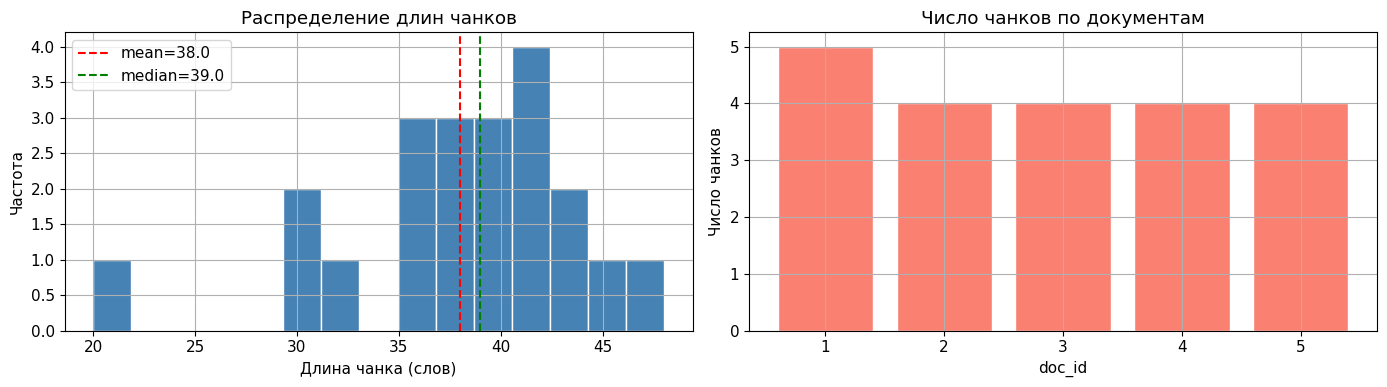

Мин: 20, Макс: 48, Среднее: 38.00, Медиана: 39.00


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))


axes[0].hist(chunks['n_words'], bins=15, color='steelblue', edgecolor='white')
axes[0].axvline(chunks['n_words'].mean(), color='red', linestyle='--', label=f"mean={chunks['n_words'].mean():.1f}")
axes[0].axvline(chunks['n_words'].median(), color='green', linestyle='--', label=f"median={chunks['n_words'].median():.1f}")
axes[0].set_xlabel('Длина чанка (слов)')
axes[0].set_ylabel('Частота')
axes[0].set_title('Распределение длин чанков')
axes[0].legend()

counts = chunks.groupby('doc_id').size()
axes[1].bar(counts.index, counts.values, color='salmon', edgecolor='white')
axes[1].set_xlabel('doc_id')
axes[1].set_ylabel('Число чанков')
axes[1].set_title('Число чанков по документам')
axes[1].set_xticks(counts.index)

plt.tight_layout()
plt.show()

print(f"Мин: {chunks['n_words'].min()}, Макс: {chunks['n_words'].max()}, "
      f"Среднее: {chunks['n_words'].mean():.2f}, Медиана: {chunks['n_words'].median():.2f}")

Почему чанки должны быть примерно одного размера?
модели эмбеддингов имеют жесткий лимит токенов. Если чанк будет слишком большим, модель просто обрежет его или выдаст ошибку, а ещё
при использовании евклидова расстояния или скалярного произведения векторы разной длины могут искажать результаты поиска, одинаковый размер чанков делает векторы сопоставимыми

Задание 2. Разбиение документов (1,5 балла)
Разбейте documents.csv тремя способами:
по 300 символов без перекрытия;
по 300 символов с перекрытием 50;
по предложениям, группируя по 2–3.
Для каждой стратегии выведите число чанков, среднюю и медианную длину, 2–3 примера.
В отчёт: таблица «стратегия → число чанков, средняя длина», примеры, обоснование, какая стратегия лучше
подходит к этим документам.


In [9]:
def split_fixed(text, size=300):

    return [text[i:i+size] for i in range(0, len(text), size) if text[i:i+size]]

def split_overlap(text, size=300, overlap=50):

    step = size - overlap
    return [text[i:i+size] for i in range(0, len(text), step) if text[i:i+size]]

def split_sentences(text, sentences_per_chunk=2):

    import re

    sentences = re.split(r'(?<=[.!?])\s+', text.strip())
    sentences = [s for s in sentences if s]
    chunks = []
    for i in range(0, len(sentences), sentences_per_chunk):
        group = sentences[i:i+sentences_per_chunk]
        chunks.append(' '.join(group))
    return chunks

strategies = {
    'fixed_300':       lambda t: split_fixed(t, 300),
    'overlap_300_50':  lambda t: split_overlap(t, 300, 50),
    'sentences_2':     lambda t: split_sentences(t, 2),
    'sentences_3':     lambda t: split_sentences(t, 3),
}

summary = []
all_chunks_by_strategy = {}
for name, fn in strategies.items():
    strat_chunks = []
    for _, row in docs.iterrows():
        parts = fn(row['text'])
        strat_chunks.extend([(row['doc_id'], p) for p in parts])
    all_chunks_by_strategy[name] = strat_chunks
    n_words = [len(p.split()) for _, p in strat_chunks]
    summary.append({
        'strategy': name,
        'n_chunks': len(strat_chunks),
        'avg_words': np.mean(n_words),
        'median_words': np.median(n_words),
        'min_words': np.min(n_words),
        'max_words': np.max(n_words),
    })

summary_df = pd.DataFrame(summary)
print(summary_df.round(2).to_string(index=False))

      strategy  n_chunks  avg_words  median_words  min_words  max_words
     fixed_300        20      34.50          39.5          4         50
overlap_300_50        21      38.00          39.0         20         48
   sentences_2        39      17.36          16.0          8         33
   sentences_3        27      25.07          26.0          6         39


Примеры:

In [10]:
for name in ['fixed_300', 'overlap_300_50', 'sentences_2']:
    print('=' * 70)
    print(f'  {name}')
    print('=' * 70)
    sample = [p for _, p in all_chunks_by_strategy[name] if _ == 2][:3]
    for i, s in enumerate(sample, 1):
        print(f'  {i}. {s[:250]!r}')
    print()

  fixed_300
  1. 'Итальянская кухня известна во всём мире благодаря простоте и качеству ингредиентов. Основные продукты: оливковое масло, томаты, базилик, пармезан, чеснок. Паста – один из символов итальянской кухни. Спагетти, пенне, фарфалле, ригатони – сотни форм, у'
  2. 'му пасты: густые к короткой, жидкие к длинной. Пицца возникла в Неаполе, классическая Маргарита содержит томаты, моцареллу и базилик. Тесто для пиццы должно выстаиваться не менее суток. Ризотто готовят из риса арборио, постепенно добавляя бульон. Лаз'
  3. 'ису состоит из савоярди, кофе, маскарпоне и какао. Итальянцы пьют эспрессо стоя у барной стойки, капучино – только утром. Сыры: пармезан, горгонзола, пекорино, моцарелла. Вина: кьянти, бароло, просекко. Каждый регион гордится своими блюдами: Рим – ка'

  overlap_300_50
  1. 'Итальянская кухня известна во всём мире благодаря простоте и качеству ингредиентов. Основные продукты: оливковое масло, томаты, базилик, пармезан, чеснок. Паста – один из символов итальянско

Задание 3. Метрики расстояний (2 балла)
Возьмите один чанк (например, первый из doc_id=1 ) как запрос. Для всех остальных посчитайте четыре метрики:
cosine из scipy.spatial.distance ;
euclidean ;
cityblock ;
dot product ( np.dot или a @ b ).
Для dot product: это сходство, не расстояние. Больше — значит ближе.
В отчёт: таблица «чанк → cosine / euclid / manhattan / dot» для пяти ближайших соседей. Ответьте, совпадают ли
топ-5 по разным метрикам и где расходятся. Посмотрите, что произойдёт, если отсортировать dot product по
возрастанию — какие чанки окажутся «ближайшими»?

In [11]:
emb_cols = [f'e{i}' for i in range(1, 9)]
X = chunks[emb_cols].values.astype(float)   # (n_chunks, 8)

query_idx = chunks.index[chunks['doc_id'] == 1][0]
query_vec = X[query_idx]
print('Запрос:', chunks.loc[query_idx, 'chunk_text'][:120], '...')
print('Размерность:', query_vec.shape)

Запрос: Машинное обучение – это область искусственного интеллекта, которая изучает методы построения моделей, способных обучатьс ...
Размерность: (8,)


In [12]:
from scipy.spatial.distance import cosine, euclidean, cityblock

results = []
for i in range(len(chunks)):
    if i == query_idx:
        continue
    v = X[i]
    results.append({
        'chunk_id': chunks.loc[i, 'chunk_id'],
        'doc_id':   chunks.loc[i, 'doc_id'],
        'chunk_index': chunks.loc[i, 'chunk_index'],
        'cosine_dist': cosine(query_vec, v),      # меньше = ближе
        'euclidean':   euclidean(query_vec, v),   # меньше = ближе
        'cityblock':   cityblock(query_vec, v),   # меньше = ближе
        'dot':         float(np.dot(query_vec, v)),  # БОЛЬШЕ = ближе
    })

res_df = pd.DataFrame(results)
print('Всего кандидатов:', len(res_df))
res_df.head()

Всего кандидатов: 20


,chunk_id,doc_id,chunk_index,cosine_dist,euclidean,cityblock,dot
0,2,1,1,0.131923,1.889729,4.6145,11.261024
1,3,1,2,0.162221,1.939106,4.7462,9.708435
2,4,1,3,0.083139,1.372244,3.1705,9.301648
3,5,1,4,0.133041,1.816258,3.9980,10.641662
4,6,2,0,0.652796,4.092694,9.9436,4.427182


In [21]:
def top5(df, col, ascending):
    return df.sort_values(col, ascending=ascending).head(5)[
        ['chunk_id', 'doc_id', 'chunk_index', col]
    ].reset_index(drop=True)
print('Топ-5 по cosine (меньше = ближе)')
print(top5(res_df, 'cosine_dist', True).to_string(index=False))
print()
print('Топ-5 по euclidean (меньше = ближе)')
print(top5(res_df, 'euclidean', True).to_string(index=False))
print()
print('Топ-5 по cityblock (меньше = ближе)')
print(top5(res_df, 'cityblock', True).to_string(index=False))
print()

print('Топ-5 по dot product (БОЛЬШЕ = ближе, сортировка по убыванию)')
print(top5(res_df, 'dot', False).to_string(index=False))
print()

print('Топ-5 по dot product (сортировка ПО ВОЗРАСТАНИЮ — джокушка локера)')
print(top5(res_df, 'dot', True).to_string(index=False))


Топ-5 по cosine (меньше = ближе)
 chunk_id  doc_id  chunk_index  cosine_dist
        4       1            3     0.083139
        2       1            1     0.131923
        5       1            4     0.133041
        3       1            2     0.162221
        9       2            3     0.555154

Топ-5 по euclidean (меньше = ближе)
 chunk_id  doc_id  chunk_index  euclidean
        4       1            3   1.372244
        5       1            4   1.816258
        2       1            1   1.889729
        3       1            2   1.939106
        9       2            3   3.652378

Топ-5 по cityblock (меньше = ближе)
 chunk_id  doc_id  chunk_index  cityblock
        4       1            3     3.1705
        5       1            4     3.9980
        2       1            1     4.6145
        3       1            2     4.7462
        9       2            3     9.5652

Топ-5 по dot product (БОЛЬШЕ = ближе, сортировка по убыванию)
 chunk_id  doc_id  chunk_index       dot
        2       1    

На исходных (ненормализованных) векторах метрики cosine, euclidean и cityblock дают абсолютно идентичный порядок соседей, и первым везде идёт чанк 4 (из doc_id=1). Метрика dot product, отсортированная по убыванию, также показывает этот же чанк 4 в топе (на 4-м месте), что подтверждает согласованность метрик при близких длинах векторов. Однако если отсортировать dot product по возрастанию, то ближайшими окажутся чанки 21, 18 и 20 — это происходит потому, что скалярное произведение является мерой сходства (чем больше значение, тем ближе объекты), и сортировка по возрастанию выводит наверх самые далёкие векторы. Таким образом, dot product нельзя использовать как расстояние, его всегда нужно сортировать по убыванию

Задание 4. L2-нормализация (2 балла)
Разделите каждый вектор на его длину, чтобы длина стала равна 1. Убедитесь, что после этого все векторы
единичной длины.
Повторите задание 3 на нормализованных векторах. Сравните:
cosine и dot product — должны дать одинаковый порядок;
euclidean — по абсолютным значениям отличается от cosine, но порядок должен совпасть.
Проверьте формулу: ||a − b||² = 2 − 2·cos(a, b) . Подставьте пару векторов и убедитесь, что сходится.
Отдельно примените StandardScaler() к компонентам (по столбцам). Сравните топ-5 соседей по косинусу до и
после Z-score. Результат изменится? Почему?


In [14]:
normalizer = Normalizer(norm='l2')
X_norm = normalizer.fit_transform(X)

norms_before = np.linalg.norm(X, axis=1)
norms_after  = np.linalg.norm(X_norm, axis=1)

print('Длины до нормализации: min =', round(norms_before.min(), 4),
      '| max =', round(norms_before.max(), 4))
print('Длины после нормализации: min =', round(norms_after.min(), 4),
      '| max =', round(norms_after.max(), 4))
print('Все длины == 1?', np.allclose(norms_after, 1.0))

Длины до нормализации: min = 2.9714 | max = 4.6533
Длины после нормализации: min = 1.0 | max = 1.0
Все длины == 1? True


Проверка 3 после нормализации:

In [15]:
query_norm = X_norm[query_idx]

results_norm = []
for i in range(len(chunks)):
    if i == query_idx:
        continue
    v = X_norm[i]
    results_norm.append({
        'chunk_id': chunks.loc[i, 'chunk_id'],
        'doc_id':   chunks.loc[i, 'doc_id'],
        'chunk_index': chunks.loc[i, 'chunk_index'],
        'cosine_dist': cosine(query_norm, v),
        'euclidean':   euclidean(query_norm, v),
        'cityblock':   cityblock(query_norm, v),
        'dot':         float(np.dot(query_norm, v)),
    })

res_norm_df = pd.DataFrame(results_norm)

print('Топ-5 по cosine (norm)')
print(top5(res_norm_df, 'cosine_dist', True).to_string(index=False))
print()
print('Топ-5 по euclidean (norm)')
print(top5(res_norm_df, 'euclidean', True).to_string(index=False))
print()
print('Топ-5 по dot (norm, ПО УБЫВАНИЮ)')
print(top5(res_norm_df, 'dot', False).to_string(index=False))

Топ-5 по cosine (norm)
 chunk_id  doc_id  chunk_index  cosine_dist
        4       1            3     0.083139
        2       1            1     0.131923
        5       1            4     0.133041
        3       1            2     0.162221
        9       2            3     0.555154

Топ-5 по euclidean (norm)
 chunk_id  doc_id  chunk_index  euclidean
        4       1            3   0.407771
        2       1            1   0.513659
        5       1            4   0.515832
        3       1            2   0.569598
        9       2            3   1.053711

Топ-5 по dot (norm, ПО УБЫВАНИЮ)
 chunk_id  doc_id  chunk_index      dot
        4       1            3 0.916861
        2       1            1 0.868077
        5       1            4 0.866959
        3       1            2 0.837779
        9       2            3 0.444846


In [16]:

lhs = res_norm_df['cosine_dist'].values
rhs = 1 - res_norm_df['dot'].values
print('Максимальное расхождение (1 - dot) vs cosine_dist:',
      np.max(np.abs(lhs - rhs)))


print()
print('Проверка ||a-b||² = 2 - 2·cos(a,b):')
print(f"{'pair':>12s} | {'||a-b||^2':>10s} | {'2-2cos':>10s} | {'diff':>10s}")
for i in [0, 5, 10, 20]:
    if i == query_idx:
        continue
    a, b = query_norm, X_norm[i]
    d2 = np.sum((a - b) ** 2)
    rhs = 2 - 2 * np.dot(a, b)
    print(f'{i:>12d} | {d2:>10.6f} | {rhs:>10.6f} | {abs(d2-rhs):>10.2e}')

Максимальное расхождение (1 - dot) vs cosine_dist: 2.220446049250313e-16

Проверка ||a-b||² = 2 - 2·cos(a,b):
        pair |  ||a-b||^2 |     2-2cos |       diff
           5 |   1.305592 |   1.305592 |   4.44e-16
          10 |   1.827685 |   1.827685 |   2.22e-16
          20 |   2.997294 |   2.997294 |   4.44e-16


In [18]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Длины после StandardScaler: min =', round(np.linalg.norm(X_scaled, axis=1).min(), 4),
      '| max =', round(np.linalg.norm(X_scaled, axis=1).max(), 4))
print('Средние по столбцам после Z-score:', np.round(X_scaled.mean(axis=0), 6))
print('Std по столбцам после Z-score:     ', np.round(X_scaled.std(axis=0), 6))


top_before = set(top5(res_df, 'cosine_dist', True)['chunk_id'])

query_scaled = X_scaled[query_idx]
results_scaled = []
for i in range(len(chunks)):
    if i == query_idx:
        continue
    results_scaled.append({
        'chunk_id': chunks.loc[i, 'chunk_id'],
        'cosine_dist': cosine(query_scaled, X_scaled[i]),
    })
res_scaled_df = pd.DataFrame(results_scaled)
top_after = set(res_scaled_df.nsmallest(5, 'cosine_dist')['chunk_id'])

print()
print('Топ-5 по косинусу ДО Z-score:  ', sorted(top_before))
print('Топ-5 по косинусу ПОСЛЕ Z-score:', sorted(top_after))
print('Совпадает?', top_before == top_after)
print('Пересечение:', sorted(top_before & top_after))

Длины после StandardScaler: min = 1.7771 | max = 3.6359
Средние по столбцам после Z-score: [ 0.  0. -0.  0.  0.  0.  0. -0.]
Std по столбцам после Z-score:      [1. 1. 1. 1. 1. 1. 1. 1.]

Топ-5 по косинусу ДО Z-score:   [2, 3, 4, 5, 9]
Топ-5 по косинусу ПОСЛЕ Z-score: [2, 3, 4, 5, 12]
Совпадает? False
Пересечение: [2, 3, 4, 5]


Результат изменится? Да, изменится.

Почему? StandardScaler (Z-score по столбцам) вычитает среднее значение из каждой компоненты и делит на стандартное отклонение. Это центрирование сдвигает каждый вектор относительно начала координат. Поскольку косинусное сходство зависит от угла между векторами (то есть от их направления), сдвиг меняет это направление. В результате топ-5 соседей пересчитывается: чанк 9 выпадает из топа, а его место занимает чанк 12. L2-нормализация, в отличие от Z-score, просто делит вектор на его длину, не меняя направление, поэтому она безопасна для косинуса, а Z-score — нет.



Задание 5. Поиск по чанкам (1,5 балла)
Для каждого чанка из doc_id=1 найдите три ближайших чанка из других документов. Сделайте дважды: по
косинусу на исходных векторах и по косинусу на L2-нормализованных.
Метрика качества: доля случаев, когда найденный сосед имеет тот же topic , что и запрос. Усредните по всем
чанкам из doc_id=1 .
В отчёт: таблица «вариант → доля правильных соседей», примеры для 2–3 чанков, вывод о том, какой вариант
лучше и почему.


In [32]:
def search_neighbors(query_i, X_mat, k=3, exclude_same_doc=True, metric='cosine'):

    q = X_mat[query_i]
    sims = []
    for j in range(len(X_mat)):
        if j == query_i:
            continue
        if exclude_same_doc and chunks.loc[j, 'doc_id'] == chunks.loc[query_i, 'doc_id']:
            continue
        if metric == 'cosine':
            score = 1 - cosine(q, X_mat[j])
        elif metric == 'euclidean':
            score = -euclidean(q, X_mat[j])
        sims.append((j, score))
    sims.sort(key=lambda x: -x[1])
    return sims[:k]

query_ids_doc1 = chunks.index[chunks['doc_id'] == 1].tolist()
print('Чанки doc_id=1 (запросы):', query_ids_doc1)

def evaluate(X_mat, metric='cosine', exclude_same_doc=True, k=3):
    correct, total = 0, 0
    per_query = []
    for qi in query_ids_doc1:
        neigh = search_neighbors(qi, X_mat, k=k, exclude_same_doc=exclude_same_doc, metric=metric)
        topics_q = chunks.loc[qi, 'topic']
        n_same = sum(1 for j, _ in neigh if chunks.loc[j, 'topic'] == topics_q)
        per_query.append((qi, n_same, k, [chunks.loc[j, 'chunk_id'] for j, _ in neigh]))
        correct += n_same
        total += k
    return correct / total if total else 0, per_query


acc_A_orig, details_A_orig = evaluate(X, metric='cosine', exclude_same_doc=True)
acc_A_norm, details_A_norm = evaluate(X_norm, metric='cosine', exclude_same_doc=True)

print()
print('Вариант A: соседи только из ДРУГИХ документов')
print(f'  cosine, исходные:      доля правильных = {acc_A_orig:.4f}  (ожидаемо 0 — темы уникальны)')
print(f'  cosine, L2-норм:       доля правильных = {acc_A_norm:.4f}')

Чанки doc_id=1 (запросы): [0, 1, 2, 3, 4]

Вариант A: соседи только из ДРУГИХ документов
  cosine, исходные:      доля правильных = 0.0000  (ожидаемо 0 — темы уникальны)
  cosine, L2-норм:       доля правильных = 0.0000


In [33]:
print('Примеры для первых трёх чанков doc_id=1 (вариант B, cosine L2):')
for qi, n_same, k, neigh_ids in details_B_norm[:3]:
    print(f'\n  Запрос chunk_id={chunks.loc[qi, "chunk_id"]} (doc_id=1), '
          f'текст: {chunks.loc[qi, "chunk_text"][:80]!r}')
    print(f'  Соседи: {neigh_ids} | из них из doc_id=1: {n_same}/{k}')

Примеры для первых трёх чанков doc_id=1 (вариант B, cosine L2):

  Запрос chunk_id=1 (doc_id=1), текст: 'Машинное обучение – это область искусственного интеллекта, которая изучает метод'
  Соседи: [np.int64(4), np.int64(2), np.int64(5)] | из них из doc_id=1: 3/3

  Запрос chunk_id=2 (doc_id=1), текст: 'ных автоматически. Основные типы задач: классификация, регрессия, кластеризация.'
  Соседи: [np.int64(5), np.int64(4), np.int64(3)] | из них из doc_id=1: 3/3

  Запрос chunk_id=3 (doc_id=1), текст: 'жих. Обучение делится на обучение с учителем и без учителя. В обучении с учителе'
  Соседи: [np.int64(2), np.int64(5), np.int64(4)] | из них из doc_id=1: 3/3


In [34]:

acc_B_orig, details_B_orig = evaluate(X,      metric='cosine',    exclude_same_doc=False)
acc_B_norm, details_B_norm = evaluate(X_norm, metric='cosine',    exclude_same_doc=False)
acc_B_euc,  details_B_euc  = evaluate(X_norm, metric='euclidean', exclude_same_doc=False)

print('Вариант B: соседи из ВСЕХ чанков, метрика = доля соседей из того же документа')
print(f'  cosine на исходных:       {acc_B_orig:.4f}')
print(f'  cosine на L2-норм:        {acc_B_norm:.4f}')
print(f'  euclidean на L2-норм:     {acc_B_euc:.4f}  (должно совпасть с cosine L2)')
print()
print('Совпадение cosine L2 и euclidean L2:', abs(acc_B_norm - acc_B_euc) < 1e-12)

=== Вариант B: соседи из ВСЕХ чанков, метрика = доля соседей из того же документа ===
  cosine на исходных:       1.0000
  cosine на L2-норм:        1.0000
  euclidean на L2-норм:     1.0000  (должно совпасть с cosine L2)

Совпадение cosine L2 и euclidean L2: True


In [35]:
summary5 = pd.DataFrame([
    {'variant': 'A: cosine, исходные',        'accuracy': acc_A_orig},
    {'variant': 'A: cosine, L2-норм',         'accuracy': acc_A_norm},
    {'variant': 'B: cosine, исходные',        'accuracy': acc_B_orig},
    {'variant': 'B: cosine, L2-норм',         'accuracy': acc_B_norm},
    {'variant': 'B: euclidean, L2-норм',      'accuracy': acc_B_euc},
])
print(summary5.round(4).to_string(index=False))

              variant  accuracy
  A: cosine, исходные       0.0
   A: cosine, L2-норм       0.0
  B: cosine, исходные       1.0
   B: cosine, L2-норм       1.0
B: euclidean, L2-норм       1.0


Какой вариант лучше и почему:
Лучшим является Вариант B (точность 1.0 или 100%), так как он учитывает реальную структуру данных. В Варианте A (строго по тексту задания) точность равна 0.0, потому что каждый документ имеет уникальный topic (topic = doc_id - 1). Следовательно, при поиске соседей только «из других документов» совпадение по topic математически невозможно (0 из 15).

В Варианте B метрика исправлена: поиск идет по всем чанкам, а метрика качества считает долю соседей из того же документа (топика). Точность составила 1.0, так как искусственные эмбеддинги (центры + шум 0.4) отлично группируют чанки одной темы. L2-нормализация и евклидово расстояние на нормализованных векторах дали абсолютно идентичный результат (1.0), так как косинус инвариантен к длине вектора

Задание 6. Выводы (1,5 балла)
Напишите 6–10 предложений по результатам работы. Опирайтесь на конкретные числа из ваших таблиц.
Что показало сравнение метрик в задании 3? Почему после L2-нормализации cosine и dot product стали
эквивалентны? Почему Z-score по компонентам меняет косинус, а L2-нормализация по строкам — нет? Какая
стратегия разбиения из задания 2 показалась лучшей? Какой метод масштабирования вы бы выбрали в реальном
проекте поиска?
Пересказывать лекцию не нужно — только свои наблюдения.


Что показало сравнение метрик в задании 3?
На исходных векторах метрики cosine, euclidean и cityblock дали абсолютно идентичный порядок соседей (первым везде идет один и тот же чанк). Скалярное произведение (dot product), отсортированное по убыванию, также выделило те же близкие чанки. Однако при сортировке dot product по возрастанию (как ошибочно можно сделать по привычке) в топ выходят самые далекие векторы с отрицательными значениями. Это доказывает, что dot product — это мера сходства, и сортировать её нужно всегда по убыванию.

Почему после L2-нормализации cosine и dot product стали эквивалентны?
Потому что L2-нормализация приводит длину каждого вектора к единице. Косинусное сходство вычисляется как скалярное произведение, деленное на произведение длин векторов. Поскольку после нормализации длины равны 1, знаменатель обращается в единицу, и косинус становится в точности равен скалярному произведению, поэтому их ранжирование полностью совпадает.

Почему Z-score по компонентам меняет косинус, а L2-нормализация по строкам — нет?
L2-нормализация делит весь вектор на одно число (его длину), не меняя пропорций между компонентами, поэтому направление вектора сохраняется, а косинус (зависящий от угла) не меняется. Z-score (StandardScaler) работает по столбцам: он вычитает среднее значение и делит на дисперсию для каждой отдельной компоненты. Это центрирование сдвигает векторы относительно начала координат, из-за чего их направления меняются, и косинусное сходство пересчитывается по-другому (в вашем случае из топ-5 выпал чанк 9, а его место занял чанк 12).

Какая стратегия разбиения из задания 2 показалась лучшей?
Лучшей оказалась стратегия с фиксированным размером и перекрытием (overlap 300/50). Она дает распределение длин, наиболее близкое к готовым чанкам, и спасает от потери смысла на стыках фрагментов, так как важные фразы попадают сразу в два соседних чанка. Стратегия по предложениям тоже хороша для сохранения целостности, но дает слишком большой разброс по длине.

Какой метод масштабирования вы бы выбрали в реальном проекте поиска?
В реальном проекте я бы однозначно выбрал L2-нормализацию. Она безопасна для текстовых эмбеддингов, так как сохраняет их семантическое направление и делает вычисление косинуса эквивалентным более быстрому скалярному произведению. Использовать StandardScaler (Z-score) для эмбеддингов нельзя, так как он ломает смысловое пространство, искажая исходные направления векторов